## Mục tiêu: so sánh và chọn ba model cho stacking

In [1]:
import json
from pathlib import Path
from itertools import combinations
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
SEED = 42
from sklearn.base import clone
import warnings
from sklearn.exceptions import ConvergenceWarning

In [2]:
X, y, _, _ = load_prepared_mnist()
X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=int)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=10000, stratify=y, random_state=SEED)
print('Train:', X_train.shape, 'Validation:', X_val.shape)
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train, y_train, test_size=10000, stratify=y_train, random_state=SEED)
print('Fit:', X_fit.shape, 'Tuning:', X_tune.shape)
# Giữ nguyên split 50k/10k khi chuyển sang stacking. Split 40k/10k chỉ dùng tuning.

Train: (50000, 784) Validation: (10000, 784)
Fit: (40000, 784) Tuning: (10000, 784)


## 1. Tinh chỉnh và refit

In [3]:
base = {
    'SVM': SVC(kernel='rbf', gamma='scale', cache_size=2000, random_state=SEED),
    'Softmax': LogisticRegression(solver='lbfgs', max_iter=300, tol=1e-4),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'KNN': KNeighborsClassifier(weights='distance', n_jobs=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'MLP512': MLPClassifier(hidden_layer_sizes=(512,), solver='adam', batch_size=256,
        learning_rate_init=0.001, max_iter=60, early_stopping=False, tol=0,
        n_iter_no_change=61, random_state=SEED),
    'MLP256_128': MLPClassifier(hidden_layer_sizes=(256,128), solver='adam', batch_size=256,
        learning_rate_init=0.001, max_iter=60, early_stopping=False, tol=0,
        n_iter_no_change=61, random_state=SEED)
}
grids = {
    'SVM': [{'C': v} for v in [1, 3, 10]],
    'Softmax': [{'C': v} for v in [0.1, 1, 10]],
    'RandomForest': [{'min_samples_leaf': v} for v in [1, 2, 4]],
    'KNN': [{'n_neighbors': v} for v in [3, 5, 7]],
    'ExtraTrees': [{'min_samples_leaf': v} for v in [1, 2, 4]],
    'MLP512': [{'alpha': v} for v in [0.001, 0.01, 0.1]],
    'MLP256_128': [{'alpha': v} for v in [0.001, 0.01, 0.1]]
}

def fit_timed(model, X, y):
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, y)
    messages = ' | '.join(str(w.message) for w in caught)
    return time.perf_counter() - t0, messages

models, best_params, tuning_rows, rows = {}, {}, [], []
proba, pred, errors = {}, {}, {}
for name, estimator in base.items():
    print('Tuning:', name, flush=True)
    scores, tuning_s = [], 0
    for params in grids[name]:
        model = clone(estimator).set_params(**params)
        seconds, message = fit_timed(model, X_fit, y_fit)
        tuning_s += seconds
        yp = model.predict(X_tune)
        f1, acc = f1_score(y_tune, yp, average='macro'), accuracy_score(y_tune, yp)
        scores.append((acc, f1))
        tuning_rows.append(dict(model=name, params=str(params), f1_macro=f1,
            accuracy=acc, fit_seconds=seconds, warning=message))
        print(params, f'F1={f1:.4f}', 'Có cảnh báo' if message else '', flush=True)
    best_params[name] = grids[name][max(range(len(scores)), key=lambda i: scores[i])]
    model = clone(estimator).set_params(**best_params[name])
    if name == 'SVM': model.set_params(probability=True)
    fit_s, message = fit_timed(model, X_train, y_train)
    models[name] = model
    t0 = time.perf_counter()
    pred[name] = model.predict(X_val)
    predict_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    proba[name] = model.predict_proba(X_val)[:, np.argsort(model.classes_)]
    proba_s = time.perf_counter() - t0
    errors[name] = pred[name] != y_val
    rows.append(dict(model=name, params=str(best_params[name]),
        accuracy=accuracy_score(y_val, pred[name]), f1_macro=f1_score(y_val, pred[name], average='macro'),
        n_errors=int(errors[name].sum()), tuning_fit_seconds=tuning_s, fit_seconds=fit_s,
        predict_seconds=predict_s, proba_seconds=proba_s, warning=message))
    print(name, 'hoàn tất; validation accuracy:', rows[-1]['accuracy'], flush=True)
tuning_results = pd.DataFrame(tuning_rows)
singles = pd.DataFrame(rows).sort_values(['accuracy', 'f1_macro'], ascending=False)
display(tuning_results.round(4))
display(singles.round(4))

Tuning: SVM


{'C': 1} F1=0.9744 
{'C': 3} F1=0.9791 
{'C': 10} F1=0.9792 
SVM hoàn tất; validation accuracy: 0.9826
Tuning: Softmax
{'C': 0.1} F1=0.9168 
{'C': 1} F1=0.9164 
{'C': 10} F1=0.9123 Có cảnh báo
Softmax hoàn tất; validation accuracy: 0.9214
Tuning: RandomForest
{'min_samples_leaf': 1} F1=0.9646 
{'min_samples_leaf': 2} F1=0.9635 
{'min_samples_leaf': 4} F1=0.9600 
RandomForest hoàn tất; validation accuracy: 0.9669
Tuning: KNN
{'n_neighbors': 3} F1=0.9692 
{'n_neighbors': 5} F1=0.9690 
{'n_neighbors': 7} F1=0.9679 
KNN hoàn tất; validation accuracy: 0.972
Tuning: ExtraTrees
{'min_samples_leaf': 1} F1=0.9675 
{'min_samples_leaf': 2} F1=0.9638 
{'min_samples_leaf': 4} F1=0.9601 
ExtraTrees hoàn tất; validation accuracy: 0.9709
Tuning: MLP512
{'alpha': 0.001} F1=0.9770 Có cảnh báo
{'alpha': 0.01} F1=0.9804 Có cảnh báo
{'alpha': 0.1} F1=0.9770 Có cảnh báo
MLP512 hoàn tất; validation accuracy: 0.9828
Tuning: MLP256_128
{'alpha': 0.001} F1=0.9794 Có cảnh báo
{'alpha': 0.01} F1=0.9795 Có cảnh bá

,model,params,f1_macro,accuracy,fit_seconds,warning
0,SVM,{'C': 1},0.9744,0.9746,135.4649,
1,SVM,{'C': 3},0.9791,0.9793,130.7024,
2,SVM,{'C': 10},0.9792,0.9794,131.6277,
3,Softmax,{'C': 0.1},0.9168,0.9180,198.7754,
4,Softmax,{'C': 1},0.9164,0.9175,663.6405,
5,Softmax,{'C': 10},0.9123,0.9135,386.7946,lbfgs failed to converge after 300 iteration(s...
6,RandomForest,{'min_samples_leaf': 1},0.9646,0.9650,10.0901,
7,RandomForest,{'min_samples_leaf': 2},0.9635,0.9639,9.5475,
8,RandomForest,{'min_samples_leaf': 4},0.9600,0.9604,8.9111,
9,KNN,{'n_neighbors': 3},0.9692,0.9694,0.0324,


,model,params,accuracy,f1_macro,n_errors,tuning_fit_seconds,fit_seconds,predict_seconds,proba_seconds,warning
5,MLP512,{'alpha': 0.01},0.9828,0.9827,172,3333.6477,859.7703,0.2705,0.4609,Stochastic Optimizer: Maximum iterations (60) ...
0,SVM,{'C': 10},0.9826,0.9825,174,397.7950,996.4819,62.0129,64.7157,The `probability` parameter was deprecated in ...
6,MLP256_128,{'alpha': 0.01},0.9819,0.9818,181,2904.7396,1034.4914,0.1437,0.0926,Stochastic Optimizer: Maximum iterations (60) ...
3,KNN,{'n_neighbors': 3},0.9720,0.9720,280,0.1517,0.0556,10.3534,9.9887,
4,ExtraTrees,{'min_samples_leaf': 1},0.9709,0.9708,291,29.6775,12.8991,0.2972,0.2276,
2,RandomForest,{'min_samples_leaf': 1},0.9669,0.9668,331,28.5487,13.2537,0.2313,0.2125,
1,Softmax,{'C': 0.1},0.9214,0.9205,786,1249.2104,242.0174,0.0209,0.0207,


## 2. Trùng lỗi giữa cặp và bộ ba

In [4]:
# Trùng lỗi = mọi model đều sai trên cùng ảnh, có thể khác nhãn sai.
# Oracle = tỷ lệ có ít nhất một model đúng.
def compare_combos(size):
    rows = []
    for combo in combinations(models, size):
        common = np.logical_and.reduce([errors[n] for n in combo]).sum()
        least = min(errors[n].sum() for n in combo)
        vote = np.mean([proba[n] for n in combo], axis=0).argmax(1)
        best_single = max(accuracy_score(y_val, pred[n]) for n in combo)
        rows.append(dict(combo=' + '.join(combo), common_errors=int(common),
            overlap_ratio=common / least if least else np.nan,
            oracle_accuracy=1 - common / len(y_val),
            voting_accuracy=accuracy_score(y_val, vote),
            voting_f1=f1_score(y_val, vote, average='macro'),
            gain_over_best=accuracy_score(y_val, vote) - best_single,
            gain_over_global_best=accuracy_score(y_val, vote) - singles.accuracy.max()))
    return pd.DataFrame(rows).sort_values(['voting_accuracy', 'voting_f1'], ascending=False).reset_index(drop=True)

pairs, triples = compare_combos(2), compare_combos(3)
print('21 cặp:'); display(pairs.round(4))
print('35 bộ ba:'); display(triples.round(4))

21 cặp:


,combo,common_errors,overlap_ratio,oracle_accuracy,voting_accuracy,voting_f1,gain_over_best,gain_over_global_best
0,SVM + MLP512,119,0.6919,0.9881,0.9846,0.9845,0.0018,0.0018
1,SVM + MLP256_128,117,0.6724,0.9883,0.9838,0.9837,0.0012,0.0010
2,SVM + ExtraTrees,129,0.7414,0.9871,0.9837,0.9837,0.0011,0.0009
3,SVM + RandomForest,135,0.7759,0.9865,0.9832,0.9831,0.0006,0.0004
4,MLP512 + MLP256_128,129,0.7500,0.9871,0.9832,0.9831,0.0004,0.0004
5,ExtraTrees + MLP512,123,0.7151,0.9877,0.9831,0.9830,0.0003,0.0003
6,RandomForest + MLP512,131,0.7616,0.9869,0.9828,0.9827,0.0000,0.0000
7,ExtraTrees + MLP256_128,119,0.6575,0.9881,0.9826,0.9825,0.0007,-0.0002
8,RandomForest + MLP256_128,129,0.7127,0.9871,0.9825,0.9824,0.0006,-0.0003
9,KNN + MLP256_128,91,0.5028,0.9909,0.9810,0.9810,-0.0009,-0.0018


35 bộ ba:


,combo,common_errors,overlap_ratio,oracle_accuracy,voting_accuracy,voting_f1,gain_over_best,gain_over_global_best
0,SVM + KNN + MLP512,82,0.4767,0.9918,0.9853,0.9853,0.0025,0.0025
1,SVM + KNN + MLP256_128,81,0.4655,0.9919,0.9852,0.9851,0.0026,0.0024
2,KNN + MLP512 + MLP256_128,77,0.4477,0.9923,0.9850,0.9849,0.0022,0.0022
3,SVM + MLP512 + MLP256_128,103,0.5988,0.9897,0.9845,0.9844,0.0017,0.0017
4,SVM + RandomForest + MLP512,97,0.5640,0.9903,0.9845,0.9844,0.0017,0.0017
5,SVM + ExtraTrees + MLP512,94,0.5465,0.9906,0.9844,0.9843,0.0016,0.0016
6,SVM + RandomForest + MLP256_128,98,0.5632,0.9902,0.9840,0.9839,0.0014,0.0012
7,ExtraTrees + MLP512 + MLP256_128,99,0.5756,0.9901,0.9840,0.9839,0.0012,0.0012
8,SVM + ExtraTrees + MLP256_128,92,0.5287,0.9908,0.9839,0.9838,0.0013,0.0011
9,RandomForest + MLP512 + MLP256_128,104,0.6047,0.9896,0.9839,0.9838,0.0011,0.0011


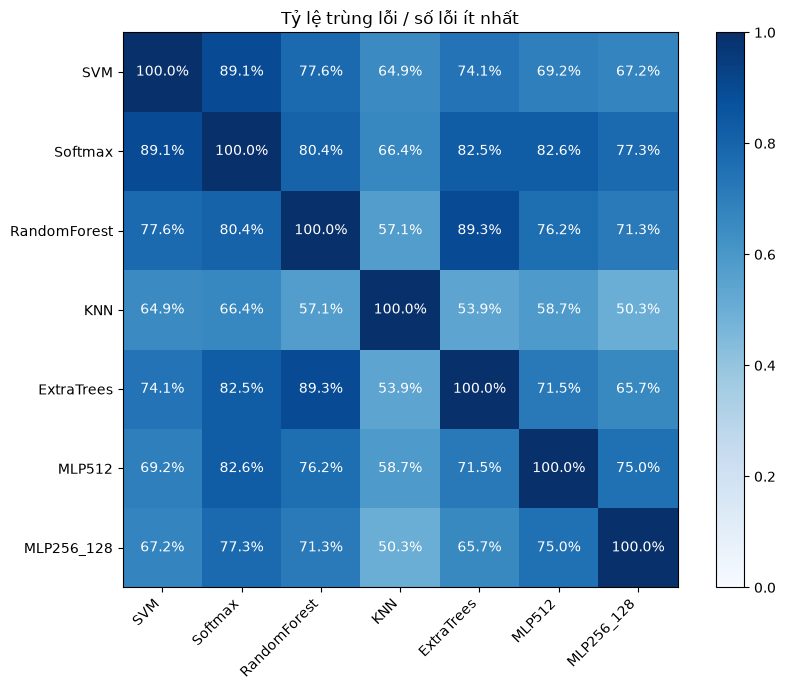

Bộ ba đề xuất: ['SVM', 'KNN', 'MLP512']
Voting accuracy: 0.9853
Accuracy model đơn tốt nhất: 0.9828


In [5]:
names = list(models)
heat = np.full((len(names), len(names)), np.nan)
for i, a in enumerate(names):
    for j, b in enumerate(names):
        least = min(errors[a].sum(), errors[b].sum())
        if least: heat[i, j] = (errors[a] & errors[b]).sum() / least
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(heat, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(names)), names, rotation=45, ha='right')
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{heat[i,j]:.1%}', ha='center', va='center',
            color='white' if heat[i,j] > 0.5 else 'black')
ax.set_title('Tỷ lệ trùng lỗi / số lỗi ít nhất')
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
# Chọn theo voting accuracy, F1 macro phá hòa. Đây là ứng viên cho stacking.
selected = triples.iloc[0]['combo'].split(' + ')
print('Bộ ba đề xuất:', selected)
print('Voting accuracy:', round(triples.iloc[0]['voting_accuracy'], 4))
print('Accuracy model đơn tốt nhất:', round(singles.accuracy.max(), 4))

## 3. Chuyển sang stacking

In [6]:
OUTPUT = ROOT / 'results' / 'combo_validation'
OUTPUT.mkdir(parents=True, exist_ok=True)
singles.to_csv(OUTPUT / 'singles.csv', index=False)
pairs.to_csv(OUTPUT / 'pairs.csv', index=False)
triples.to_csv(OUTPUT / 'triples.csv', index=False)
np.savez_compressed(OUTPUT / 'validation_proba.npz', y_val=y_val, **proba)
(OUTPUT / 'selected_models.txt').write_text('\n'.join(selected), encoding='utf-8')
print('Đã lưu:', OUTPUT)
tuning_results.to_csv(OUTPUT / 'tuning.csv', index=False)
(OUTPUT / 'best_params.json').write_text(json.dumps(best_params, indent=2), encoding='utf-8')

Đã lưu: d:\midterm_pattern_recognition\mnist-pattern-recognition\results\combo_validation


278